# Phase 2 — Neuro-Symbolic Causal Inference: the DL pipeline

Phase 1 showed two things:
1. **Reasoning beats wording.** Rules + PC algorithm + a depth-4 tree reach F1 ≈ 1.0, and renaming the variables does not hurt.
2. **The language layer is the weak spot.** The regex parser reads **0 %** of re-worded (paraphrased) hypotheses,
   so the whole system scores 0 there. A text-only model (TF-IDF) learns a shortcut and collapses when variables are renamed.

Phase 2 brings in a transformer (**DistilBERT**, 66 M parameters) in two ways, each paired with its Phase 1 counterpart:

| | text only (no reasoning layer) | language layer + reasoning layer (hybrid / neuro-symbolic) |
|---|---|---|
| ML (Phase 1) | TF-IDF + LR | Rules + PC + Decision Tree |
| DL (Phase 2) | **2A: DistilBERT end-to-end** | **2B: DistilBERT parser + PC + Decision Tree** |

```
2A   [CLS] hypothesis [SEP] premise [SEP] ──DistilBERT──▶ valid / not valid

2B   hypothesis ──DistilBERT parser──▶ (relation, X, Y) ─┐
     premise    ──regex facts──▶ PC algorithm ──────────────┴─▶ features ─▶ decision tree ─▶ valid triples ─▶ DAG ─▶ BN ─▶ do-queries
                                  (unchanged from Phase 1)
```

Evaluation is identical to Phase 1: same splits, same precision / recall / F1 of the valid class, same graph-stage code
(edge precision + known intervention queries).

**Model choice.** `distilbert-base-cased`. *Cased* because the variables are capital letters:
an uncased model would turn the variable `A` into the word `a`.

In [1]:
import sys, json, random, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

from causal_nlp.data import load_split, load_refactorization_test, load_paraphrase_test, PARAPHRASE_PATTERNS
from causal_nlp.parsing import parse_hypothesis, Hypothesis
from causal_nlp.features import build_feature_table, analyse_premise, ALL_FEATURES
from causal_nlp import graph_stage as gs
from causal_nlp import dl_common, dl_end2end, dl_parser
from causal_nlp.dl_common import MODELS_DIR, pick_device

SEED = 42
RESULTS = ROOT / "results"
FIGURES = ROOT / "report" / "figures"  # PDF copies of the figures for the report
FIGURES.mkdir(parents=True, exist_ok=True)
EVAL_SETS = ["dev", "test", "refactorization", "paraphrase"]
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("device:", pick_device())

device: mps


## 1. Data (same five sets as Phase 1)

In [2]:
data = {
    "train": load_split("train"),
    "dev": load_split("dev"),
    "test": load_split("test"),
    "refactorization": load_refactorization_test(),
    "paraphrase": load_paraphrase_test(),
}
phase1 = pd.read_csv(RESULTS / "phase1_metrics.csv")
pd.DataFrame({name: {"rows": len(df), "premises": df.premise.nunique(), "% valid": round(100 * df.label.mean(), 1)}
              for name, df in data.items()}).T

,rows,premises,% valid
train,205734.0,2338.0,21.0
dev,1076.0,22.0,14.8
test,1162.0,21.0,16.5
refactorization,2246.0,21.0,16.2
paraphrase,2246.0,21.0,16.2


## 2. Training (done once by `tools/train_phase2.py`)

| model | training data | epochs | time |
|---|---|---|---|
| 2B parser | 18 k short sentences: original templates + our grammar (§4) | 3 | ≈ 3 min |
| 2A end-to-end | 12 k (premise, hypothesis) pairs sampled from train | 2 | 18–42 min* |
| 2A + renaming | the same 12 k pairs, half with variables renamed at random | 2 | 18–42 min* |

\* Apple-laptop GPU, batch 8; the time varied with other load on the machine. 12 k rows and batch 8 are
laptop memory limits — on a Colab GPU: `END2END_ROWS=40000 END2END_BATCH=16 python tools/train_phase2.py end2end`.

**Training loop** (`dl_common.train_classifier`, plain PyTorch so every step is visible): tokenise →
batches of similar length → DistilBERT → class-weighted cross-entropy → backward → AdamW → after each epoch
score the dev set and keep the best epoch.

**Regularization** (fine-tuning 66 M parameters on a few thousand examples overfits easily):

| technique | where | why |
|---|---|---|
| dropout 0.1 | inside DistilBERT (default) | standard transformer regularization |
| weight decay 0.01 (AdamW) | all models | keeps weights small |
| early stopping on dev | all models | keep the epoch with the best dev score |
| warm-up + linear decay, gradient clipping 1.0 | all models | stable fine-tuning, no exploding steps |
| class-weighted loss | all models | only ≈ 21 % of claims are valid |
| variable-renaming augmentation | 2A + renaming | removes the "alphabetical = causal order" shortcut |
| grammar data + held-out-verb validation | 2B parser | stops it memorising single keywords (§4) |

In [3]:
for name in ("parser", "end2end", "end2end_renamed"):
    if not (MODELS_DIR / name / "training_info.json").exists():
        print("training", name, "...")
        subprocess.run([sys.executable, str(ROOT / "tools" / "train_phase2.py"), name], check=True)

info = {name: json.loads((MODELS_DIR / name / "training_info.json").read_text())
        for name in ("parser", "end2end", "end2end_renamed")}
print("Per epoch: training loss and dev score (parser: accuracy on held-out verbs; 2A: dev F1)")
pd.DataFrame([{"model": name, "epoch": h["epoch"], "train loss": round(h["train_loss"], 4),
               "dev score": round(h["dev_score"], 4), "minutes so far": round(h["seconds"] / 60, 1)}
              for name, i in info.items() for h in i["history"]]).set_index(["model", "epoch"])

Per epoch: training loss and dev score (parser: accuracy on held-out verbs; 2A: dev F1)


train loss  dev score  minutes so far
model           epoch                                       
parser          1          0.2584     1.0000             1.0
                2          0.0003     1.0000             2.1
                3          0.0002     1.0000             3.1
end2end         1          0.4529     0.5327            33.4
                2          0.2988     0.5475            42.3
end2end_renamed 1          0.6395     0.4789             8.7
                2          0.4243     0.5542            17.6

## 3. System 2A — DistilBERT end-to-end

Input: `[CLS] hypothesis [SEP] premise [SEP]`, at most 512 tokens. The hypothesis goes first, so if a long
premise must be cut only its tail is lost. Output: P(valid). Predicted valid if P ≥ 0.5.

**Training sample.** 12 k rows drawn at random from train, stratified by template × label, keeping only inputs that
fit in 512 tokens (every test input fits; a cut-off premise could hide the very fact the label depends on).

**Renaming augmentation.** In Corr2Cause the variables are named in causal order (A usually causes B), a shortcut
that a text model can learn instead of reasoning. For half of the training rows we give the variables new random
letters (same mapping in premise and hypothesis — the facts and the label do not change). Example:

In [4]:
row = data["test"].iloc[5]
premise, hypothesis = dl_end2end.rename_variables(row.premise, row.hypothesis, random.Random(0))
print("original:", row.hypothesis, "|", row.premise[:150], "...")
print("renamed :", hypothesis, "|", premise[:150], "...")

original: There exists at least one confounder (i.e., common cause) of A and B. | Suppose there is a closed system of 2 variables, A and B. All the statistical relations among these 2 variables are as follows: A correlates with B. ...
renamed : There exists at least one confounder (i.e., common cause) of M and Y. | Suppose there is a closed system of 2 variables, M and Y. All the statistical relations among these 2 variables are as follows: M correlates with Y. ...


In [5]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODELS_DIR / "end2end")
too_long = {s: np.mean([len(r) > 512 for r in dl_common.encode(tokenizer, data[s].hypothesis, data[s].premise, 10_000)])
            for s in EVAL_SETS}
pd.Series(too_long).map("{:.1%}".format).to_frame("inputs longer than 512 tokens (premise tail cut)")

,inputs longer than 512 tokens (premise tail cut)
dev,25.1%
test,0.0%
refactorization,0.0%
paraphrase,0.0%


In [6]:
def scores(y_true, y_pred):
    return {"precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}

def score_table(results):
    # F1 on every set + precision / recall on test
    return pd.DataFrame({name: {**{f"{s} F1": r[s]["f1"] for s in EVAL_SETS},
                                "test precision": r["test"]["precision"], "test recall": r["test"]["recall"]}
                         for name, r in results.items()}).T.round(3)

end2end_prob, end2end_results = {}, {}
for name in ("end2end", "end2end_renamed"):
    model, tok, _ = dl_common.load(MODELS_DIR / name)
    end2end_prob[name] = {s: dl_end2end.valid_probability(model, tok, data[s]) for s in EVAL_SETS}
    end2end_results[name] = {s: scores(data[s].label, end2end_prob[name][s] >= 0.5) for s in EVAL_SETS}
    del model
score_table(end2end_results)

W1113 11:04:34.936000 41937 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,dev F1,test F1,refactorization F1,paraphrase F1,test precision,test recall
end2end,0.547,0.653,0.377,0.489,0.510,0.906
end2end_renamed,0.554,0.633,0.592,0.499,0.487,0.901


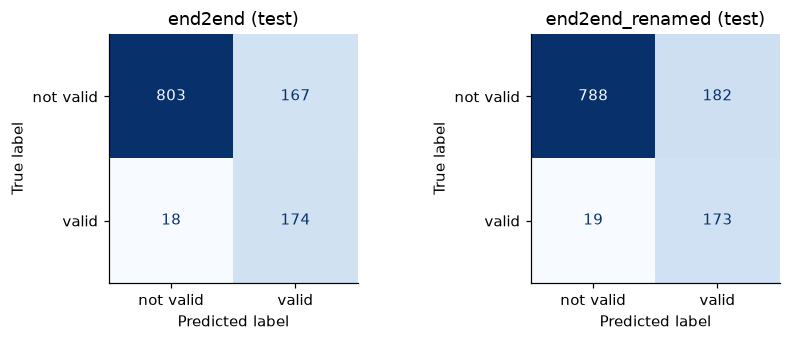

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, name in zip(axes, end2end_prob):
    ConfusionMatrixDisplay.from_predictions(data["test"].label, end2end_prob[name]["test"] >= 0.5,
                                            display_labels=["not valid", "valid"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name} (test)")
plt.tight_layout(); plt.savefig(FIGURES / "fig2_confusion_2a.pdf"); plt.show()

## 4. System 2B — DistilBERT as the language layer (hybrid ML + DL)

DistilBERT replaces **only** the regex hypothesis parser. Everything after it (PC algorithm, features,
decision tree, graph stage) is the Phase 1 code, unchanged.

**What the parser predicts.** The variables are the single capital letters in order of appearance (same as the regex).
DistilBERT reads the sentence and picks one of 6 labels — the relation type *and* its direction:

| label | example | becomes |
|---|---|---|
| `direct` | *A directly causes B* | direct(A, B) |
| `direct_reversed` | *B is directly caused by A* | direct(A, B) |
| `indirect` / `indirect_reversed` | *A causes B via an intermediate variable* / *B is an indirect effect of A* | indirect(A, B) |
| `collider` | *A and B share a common effect* | collider(A, B) |
| `confounder` | *Another variable causes both A and B* | confounder(A, B) |

A sentence that does not name exactly two different variables (e.g. a self-loop "A causes A") is rejected.

**Training data.** The original Corr2Cause templates plus sentences from a small **grammar** we wrote
(`paraphrase_grammar.py`): 8 verbs × active / passive voice × "directly" / "via another variable" × "another / a third /
a shared variable" + noun forms ("a common cause of"). Every class uses the same verbs and the same "third variable"
phrases, so the model cannot cheat with single keywords: it has to read *who causes whom*.
A first attempt with ~40 hand-written sentences overfitted to keywords (58 % on held-out wordings), which is why we use a grammar.

**No test leakage.** The paraphrase test set uses *affects*, *influences … through some mediator(s)*, *together cause
some other variable(s)*, *Some variable(s) cause(s) both*. None of these words appear in the training grammar
(`check_no_test_leak` fails otherwise). **Validation** = every grammar sentence with the verbs *triggers* / *generates*,
which are removed from training — a check on verbs the model has never seen.

In [8]:
train_templates, val_templates = dl_parser.training_templates()  # runs the leak check
print("templates per relation (train / validation):",
      {rel: (len(train_templates[rel]), len(val_templates[rel])) for rel in train_templates})
rng = random.Random(1)
for rel, items in train_templates.items():
    for template in rng.sample(items, 2):
        print(f"  {rel:10s} {dl_parser.template_label(template, rel):18s} {template.format(x='P', y='Q')}")

templates per relation (train / validation): {'direct': (70, 20), 'indirect': (82, 24), 'collider': (135, 40), 'confounder': (135, 40)}
  direct     direct_reversed    Q is produced by P with nothing in between.
  direct     direct_reversed    Q is caused by P without any intermediate variable.
  indirect   indirect_reversed  Q is driven by P through another variable.
  indirect   indirect           P produces Q by way of other variables.
  collider   collider           P and Q share a shared outcome.
  collider   collider           One other variable is determined by P and also by Q.
  confounder confounder         P and Q share a common cause.
  confounder confounder         The common variable controls P and also Q.


**Relation extraction on its own.** Does the parser read the right relation, both variables and the direction?
Gold answers: the regex for the original wording, the 4 known patterns for the paraphrase set, the grammar for held-out verbs.

In [9]:
parser = dl_parser.DistilBertParser(MODELS_DIR / "parser")

def gold_paraphrase(text):
    for pattern, relation in PARAPHRASE_PATTERNS:
        m = pattern.match(text.strip())
        if m:
            return Hypothesis(relation, *m.groups())

def same_claim(pred, gold):  # collider / confounder are symmetric: order of X and Y does not matter
    if pred is None or gold is None:
        return False
    if pred.relation in ("collider", "confounder"):
        return pred.relation == gold.relation and {pred.x, pred.y} == {gold.x, gold.y}
    return pred == gold

val_sentences = dl_parser.make_examples(val_templates, 500, seed=3)
checks = {
    "test": (data["test"].hypothesis, [parse_hypothesis(h) for h in data["test"].hypothesis]),
    "refactorization": (data["refactorization"].hypothesis, [parse_hypothesis(h) for h in data["refactorization"].hypothesis]),
    "paraphrase": (data["paraphrase"].hypothesis, [gold_paraphrase(h) for h in data["paraphrase"].hypothesis]),
    "held-out verbs": (val_sentences.text, [Hypothesis(r, x, y) for r, x, y in
                                            zip(val_sentences.relation, val_sentences.x, val_sentences.y)]),
}
readers = {"regex parser (Phase 1)": lambda texts: [parse_hypothesis(t) for t in texts],
           "DistilBERT parser (2B)": parser.parse_many}
accuracy = {name: {s: np.mean([same_claim(p, g) for p, g in zip(read(list(texts)), gold)])
                   for s, (texts, gold) in checks.items()}
            for name, read in readers.items()}
print("Share of hypotheses read correctly (relation + both variables + direction)")
pd.DataFrame(accuracy).T.map("{:.1%}".format)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Share of hypotheses read correctly (relation + both variables + direction)


,test,refactorization,paraphrase,held-out verbs
regex parser (Phase 1),100.0%,100.0%,0.0%,0.0%
DistilBERT parser (2B),100.0%,100.0%,100.0%,100.0%


**Try it on sentences written for this demo** (none of them is in the training data):

In [10]:
demo = ["W is caused directly by Z.", "Z indirectly affects W.", "Q and R together produce some outcome.",
        "K and M are both driven by some hidden factor.", "There is a variable which both F and G cause.",
        "H brings about J with no step in between.", "L and N have a common parent.",
        "Changing D has an effect on E only through C."]
pd.DataFrame({"sentence": demo, "parsed": parser.parse_many(demo)})

,sentence,parsed
0,W is caused directly by Z.,"Hypothesis(relation='direct', x='Z', y='W')"
1,Z indirectly affects W.,"Hypothesis(relation='indirect', x='Z', y='W')"
2,Q and R together produce some outcome.,"Hypothesis(relation='collider', x='Q', y='R')"
3,K and M are both driven by some hidden factor.,"Hypothesis(relation='confounder', x='K', y='M')"
4,There is a variable which both F and G cause.,"Hypothesis(relation='confounder', x='F', y='G')"
5,H brings about J with no step in between.,"Hypothesis(relation='direct', x='H', y='J')"
6,L and N have a common parent.,"Hypothesis(relation='collider', x='L', y='N')"
7,Changing D has an effect on E only through C.,None


The last sentence names three variables (D, E, C), so the parser rejects it (`None`) instead of guessing.

### 4.1 Plug the parser into the Phase 1 reasoning layer
The decision tree is the Phase 1 model (depth 4, all 23 features), retrained here on the train split exactly as before.
For train the regex parser is enough (train uses the original templates); at test time the DistilBERT parser reads every hypothesis.

In [11]:
train_feats = build_feature_table(data["train"].input)
tree = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(train_feats[ALL_FEATURES], data["train"].label)

def tree_predict(feats):
    # P(valid) from the tree; a hypothesis that could not be parsed is predicted "not valid"
    prob = np.zeros(len(feats))
    ok = (feats.parsed == 1).values
    if ok.any():
        prob[ok] = tree.predict_proba(feats.loc[ok, ALL_FEATURES])[:, 1]
    return prob

P1, P2B = "Rules + PC + DT (Phase 1)", "DistilBERT parser + PC + DT (2B)"
pipeline_feats, pipeline_results = {}, {}
for name, reader in [(P1, parse_hypothesis), (P2B, parser)]:
    pipeline_feats[name] = {}
    for s in EVAL_SETS:
        if reader is parser:
            parser.parse_many(data[s].hypothesis)  # one batched GPU pass, then cached
        pipeline_feats[name][s] = build_feature_table(data[s].input, hypothesis_parser=reader)
    pipeline_results[name] = {s: scores(data[s].label, tree_predict(pipeline_feats[name][s]) >= 0.5) for s in EVAL_SETS}
score_table(pipeline_results)

,dev F1,test F1,refactorization F1,paraphrase F1,test precision,test recall
Rules + PC + DT (Phase 1),1.0,0.997,0.997,0.000,1.0,0.995
DistilBERT parser + PC + DT (2B),1.0,0.997,0.997,0.997,1.0,0.995


## 5. Graph stage: DAGs, Bayesian networks and do-queries

Same code as Phase 1 (`graph_stage.py`). Only **reviewed** predictions go into the graph: triples the model calls valid
(P ≥ 0.5) → acyclic DAG (self-loops and cycle-closing edges rejected) → noisy-OR Bayesian network (pgmpy) →
"does do(X) change Y?" for the 242 known queries. Gold edges and queries come from the test labels (73 direct-cause edges).

* **2A** only outputs yes / no — it does not say *which* claim it judged. To place its probabilities as edges we have to borrow
  the regex reading of the test hypotheses. On paraphrased text this is impossible (the regex reads nothing), so 2A has no graph there.
* **2B** produces structured triples itself, so it can build graphs from the **paraphrased** text too.

In [12]:
test = data["test"]
test_regex = build_feature_table(test.input)  # gold reading of each test hypothesis
gold_triples = pd.DataFrame({"premise_id": test.premise_id, "relation": test_regex.relation, "x": test_regex.x,
                             "y": test_regex.y, "label": test.label})
premise_info = {pid: analyse_premise(p)[0] for pid, p in test.groupby("premise_id").premise.first().items()}
nodes = {pid: f.variables for pid, f in premise_info.items()}
queries = gs.known_intervention_queries(gold_triples, {pid: (f.variables, f.correlated) for pid, f in premise_info.items()})
pid_of_premise = dict(zip(test.premise, test.premise_id))

def triples_from(feats, df, prob):
    ok = (feats.parsed == 1).values
    cols = feats.reindex(columns=["relation", "x", "y"])  # no such columns if nothing could be parsed
    return pd.DataFrame({"premise_id": df.premise.map(pid_of_premise).values[ok], "relation": cols.relation.values[ok],
                         "x": cols.x.values[ok], "y": cols.y.values[ok], "prob": prob[ok]})

graph_rows, graph_dags = {}, {}
def evaluate_graph(key, triples):
    dags = gs.dags_from_triples(triples, nodes)
    edges = gs.edge_metrics(dags, gold_triples)
    answered = gs.answer_queries(queries, dags)
    graph_dags[key] = dags
    graph_rows[key] = {"edges correct": f"{edges['correct']}/{edges['gold_edges']}", "edge_precision": edges["edge_precision"],
                       "edge_recall": edges["edge_recall"],
                       "query_accuracy": (answered.gold_effect == answered.predicted_effect).mean()}

for name in end2end_prob:
    evaluate_graph((f"2A {name}", "test"), triples_from(test_regex, test, end2end_prob[name]["test"]))
for name, feats in pipeline_feats.items():
    for s in ("test", "paraphrase"):
        evaluate_graph((name, s), triples_from(feats[s], data[s], tree_predict(feats[s])))
graph_table = pd.DataFrame(graph_rows).T
graph_table.index.names = ["system", "text the triples were read from"]
graph_table

edges correct  \
system                           text the triples were read from                 
2A end2end                       test                                    66/73   
2A end2end_renamed               test                                    66/73   
Rules + PC + DT (Phase 1)        test                                    73/73   
                                 paraphrase                               0/73   
DistilBERT parser + PC + DT (2B) test                                    73/73   
                                 paraphrase                              73/73   

                                                                 edge_precision  \
system                           text the triples were read from                  
2A end2end                       test                                  0.616822   
2A end2end_renamed               test                                   0.52381   
Rules + PC + DT (Phase 1)        test                                       1.0   
                                 paraphrase                                 0.0   
DistilBERT parser + PC + DT (2B) test                                       1.0   
                                 paraphrase                                 1.0   

                                                                 edge_recall  \
system                           text the triples were read from               
2A end2end                       test                                0.90411   
2A end2end_renamed               test                                0.90411   
Rules + PC + DT (Phase 1)        test                                    1.0   
                                 paraphrase                              0.0   
DistilBERT parser + PC + DT (2B) test                                    1.0   
                                 paraphrase                              1.0   

                                                                 query_accuracy  
system                           text the triples were read from                 
2A end2end                       test                                  0.950413  
2A end2end_renamed               test                                  0.942149  
Rules + PC + DT (Phase 1)        test                                  0.975207  
                                 paraphrase                            0.632231  
DistilBERT parser + PC + DT (2B) test                                  0.975207  
                                 paraphrase                            0.975207

From paraphrased text the Phase 1 system builds **empty graphs** (it reads nothing, so it can only answer "no").
2B rebuilds the same causal graphs as from the original wording.

**One example.** A test premise, its paraphrased hypotheses, the DAG 2B builds from them, and a few do-queries
answered on that DAG's Bayesian network.

Suppose there is a closed system of 6 variables, A, B, C, D, E and F. All the statistical relations among these 6 variables are as follows: A correlates with B. A correlates with C. A correlates with D. A correlates with E. A correlates with F. B correlates with C. B correlates with D. B correlates with E. B correlates with F. C correlates with D. C correlates with E. C correlates with F. D correl ...

some paraphrased hypotheses:
  A directly affects B.
  A influences B through some mediator(s).
  B directly affects A.
  B influences A through some mediator(s).


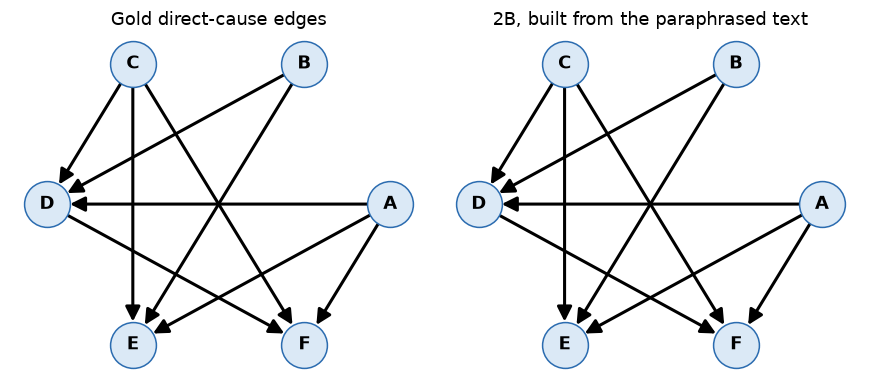

,query,gold_effect,effect,predicted_effect
49,does do(A) change D?,True,0.545,True
50,does do(A) change E?,True,0.545,True
51,does do(A) change F?,True,0.612,True
52,does do(B) change D?,True,0.545,True
53,does do(B) change E?,True,0.545,True
54,does do(B) change F?,True,0.328,True
55,does do(C) change D?,True,0.545,True
56,does do(C) change E?,True,0.545,True


In [13]:
gold_direct = gold_triples[(gold_triples.relation == "direct") & (gold_triples.label == 1)]
pid = gold_direct.premise_id.value_counts().index[0]  # the premise with the most gold edges
para = data["paraphrase"]
print(test[test.premise_id == pid].premise.iloc[0][:400], "...\n")
print("some paraphrased hypotheses:", *para[para.premise.map(pid_of_premise) == pid].hypothesis.head(4), sep="\n  ")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
gold_edges = gold_direct[gold_direct.premise_id == pid]
panels = [("Gold direct-cause edges", list(zip(gold_edges.x, gold_edges.y))),
          ("2B, built from the paraphrased text", list(graph_dags[(P2B, "paraphrase")][pid].edges))]
for ax, (title, edges) in zip(axes, panels):
    g = nx.DiGraph(edges); g.add_nodes_from(nodes[pid])
    nx.draw_networkx(g, nx.circular_layout(sorted(g.nodes)), ax=ax, node_color="#dbe9f6", edgecolors="#2b6cb0",
                     node_size=900, arrowsize=20, width=2, font_weight="bold")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.savefig(FIGURES / "fig2_dag_paraphrase.pdf"); plt.show()

example = gs.answer_queries(queries[queries.premise_id == pid], graph_dags[(P2B, "paraphrase")])
example.assign(query=[f"does do({x}) change {y}?" for x, y in zip(example.x, example.y)],
               effect=example.effect.round(3))[["query", "gold_effect", "effect", "predicted_effect"]].head(8)

`effect` = P(Y=1 | do(X=1)) − P(Y=1 | do(X=0)) on the noisy-OR network; the answer is "yes" if it is above 0.01.

## 6. Error analysis

In [14]:
rows = []
for name in end2end_prob:
    wrong = (end2end_prob[name]["test"] >= 0.5) != test.label.values
    rows.append(pd.DataFrame({"system": name, "relation": test_regex.relation.values,
                              "variables": test.num_variables.values, "wrong": wrong}))
errors = pd.concat(rows)
print("2A error rate on test, by relation type and by number of variables")
display(errors.pivot_table(index="relation", columns="system", values="wrong", aggfunc="mean").round(3))
display(errors.pivot_table(index="variables", columns="system", values="wrong", aggfunc="mean").round(3))

2A error rate on test, by relation type and by number of variables


system,end2end,end2end_renamed
relation,,
collider,0.492,0.435
confounder,0.052,0.067
direct,0.124,0.173
indirect,0.082,0.095


system,end2end,end2end_renamed
variables,,
2,0.167,0.167
3,0.167,0.271
4,0.250,0.236
5,0.210,0.245
6,0.096,0.084


In [15]:
wrong = test.assign(relation=test_regex.relation.values, prob=end2end_prob["end2end_renamed"]["test"].round(3))
wrong = wrong[(wrong.prob >= 0.5) != (wrong.label == 1)]
print(f"{len(wrong)} wrong test predictions for end2end_renamed; 20 of them:")
wrong.sample(min(20, len(wrong)), random_state=SEED)[["num_variables", "relation", "hypothesis", "label", "prob"]]

201 wrong test predictions for end2end_renamed; 20 of them:


,num_variables,relation,hypothesis,label,prob
459,5,direct,C directly causes E.,0,0.821
85,4,direct,A directly causes C.,0,0.847
125,4,collider,"There exists at least one collider (i.e., common effect) of C and D.",0,0.926
647,6,direct,E directly causes F.,0,0.648
595,5,collider,"There exists at least one collider (i.e., common effect) of B and D.",0,0.960
573,5,collider,"There exists at least one collider (i.e., common effect) of A and E.",0,0.880
324,5,indirect,A causes something else which causes E.,0,0.925
843,6,direct,A directly causes C.,1,0.187
884,6,direct,C directly causes F.,0,0.801
195,5,direct,B directly causes D.,1,0.456


In [16]:
for s in EVAL_SETS:
    pred = tree_predict(pipeline_feats[P2B][s]) >= 0.5
    print(f"2B wrong on {s:16s}: {int((pred != data[s].label.values).sum())} of {len(pred)}")
para_pred = (tree_predict(pipeline_feats[P2B]["paraphrase"]) >= 0.5).astype(int)
para_wrong = data["paraphrase"].assign(parsed=parser.parse_many(data["paraphrase"].hypothesis), pred=para_pred)
para_wrong[para_wrong.pred != para_wrong.label][["hypothesis", "parsed", "label", "pred"]]

2B wrong on dev             : 0 of 1076
2B wrong on test            : 1 of 1162
2B wrong on refactorization : 2 of 2246
2B wrong on paraphrase      : 2 of 2246


,hypothesis,parsed,label,pred
1935,Some variable(s) cause(s) both E and F.,"Hypothesis(relation='confounder', x='E', y='F')",1,0
1965,Some variable(s) cause(s) both F and E.,"Hypothesis(relation='confounder', x='F', y='E')",1,0


**Reading the errors**
* 2A's mistakes are reasoning mistakes: it has to rediscover the PC algorithm from 12 k examples. Almost half of its
  collider claims are wrong: a collider needs an *independence* fact plus two correlations, the hardest pattern to learn.
* 2B's few mistakes are the *same* as Phase 1 on the original text (a quirk of the dataset generator for confounders) —
  the parser reads each of those hypotheses correctly, so the language layer adds no new errors.

## 7. Final comparison and ablations

In [17]:
def summary(model, kind, results, graph=None, para_graph=None, trained=None):
    r = {"model": model, "type": kind, **{f"{s}_f1": results[s]["f1"] for s in EVAL_SETS},
         "test_precision": results["test"].get("precision"), "test_recall": results["test"].get("recall")}
    if graph:
        r.update(edge_precision=graph["edge_precision"], edge_recall=graph["edge_recall"],
                 intervention_query_accuracy=graph["query_accuracy"])
    if para_graph:
        r.update(paraphrase_edge_recall=para_graph["edge_recall"], paraphrase_query_accuracy=para_graph["query_accuracy"])
    if trained:
        r.update(train_minutes=trained["history"][-1]["seconds"] / 60, parameters_M=trained["n_parameters"] / 1e6)
    return r

tfidf = phase1.set_index("model").loc["TF-IDF + LR (text only)"]
final = pd.DataFrame([
    summary("TF-IDF + LR", "ML, text only", {s: {"f1": tfidf[f"{s}_f1"]} for s in EVAL_SETS}),
    summary("Rules + PC + Decision Tree", "ML, hybrid", pipeline_results[P1], graph_rows[(P1, "test")], graph_rows[(P1, "paraphrase")]),
    summary("DistilBERT end-to-end", "DL, text only", end2end_results["end2end"],
            graph_rows[("2A end2end", "test")], trained=info["end2end"]),
    summary("DistilBERT end-to-end + renaming", "DL, text only", end2end_results["end2end_renamed"],
            graph_rows[("2A end2end_renamed", "test")], trained=info["end2end_renamed"]),
    summary("DistilBERT parser + PC + Decision Tree", "DL, hybrid", pipeline_results[P2B],
            graph_rows[(P2B, "test")], graph_rows[(P2B, "paraphrase")], trained=info["parser"]),
])
final.to_csv(RESULTS / "phase2_final_comparison.csv", index=False)
final.set_index("model").drop(columns="type").T.round(3)

model,TF-IDF + LR,Rules + PC + Decision Tree,DistilBERT end-to-end,DistilBERT end-to-end + renaming,DistilBERT parser + PC + Decision Tree
dev_f1,0.606,1.000,0.547,0.554,1.000
test_f1,0.655,0.997,0.653,0.633,0.997
refactorization_f1,0.322,0.997,0.377,0.592,0.997
paraphrase_f1,0.250,0.000,0.489,0.499,0.997
test_precision,NaN,1.000,0.510,0.487,1.000
test_recall,NaN,0.995,0.906,0.901,0.995
edge_precision,NaN,1.000,0.617,0.524,1.000
edge_recall,NaN,1.000,0.904,0.904,1.000
intervention_query_accuracy,NaN,0.975,0.950,0.942,0.975
paraphrase_edge_recall,NaN,0.000,NaN,NaN,1.000


**Ablations.** Each row changes one part of the system and keeps the rest fixed:

In [18]:
f = final.set_index("model")
ablations = [
    ("renaming augmentation (2A)", "off → on", "refactorization_f1", "DistilBERT end-to-end", "DistilBERT end-to-end + renaming"),
    ("language layer (reasoning fixed: PC + tree)", "regex → DistilBERT", "paraphrase_f1",
     "Rules + PC + Decision Tree", "DistilBERT parser + PC + Decision Tree"),
    ("reasoning layer (DistilBERT in both)", "none → PC + tree", "test_f1",
     "DistilBERT end-to-end", "DistilBERT parser + PC + Decision Tree"),
    ("text-only model", "TF-IDF → DistilBERT", "paraphrase_f1", "TF-IDF + LR", "DistilBERT end-to-end"),
]
pd.DataFrame([{"what changes": a, "change": c, "metric": m, "before": round(f.loc[b, m], 3), "after": round(f.loc[x, m], 3)}
              for a, c, m, b, x in ablations])

,what changes,change,metric,before,after
0,renaming augmentation (2A),off → on,refactorization_f1,0.377,0.592
1,language layer (reasoning fixed: PC + tree),regex → DistilBERT,paraphrase_f1,0.000,0.997
2,reasoning layer (DistilBERT in both),none → PC + tree,test_f1,0.653,0.997
3,text-only model,TF-IDF → DistilBERT,paraphrase_f1,0.250,0.489


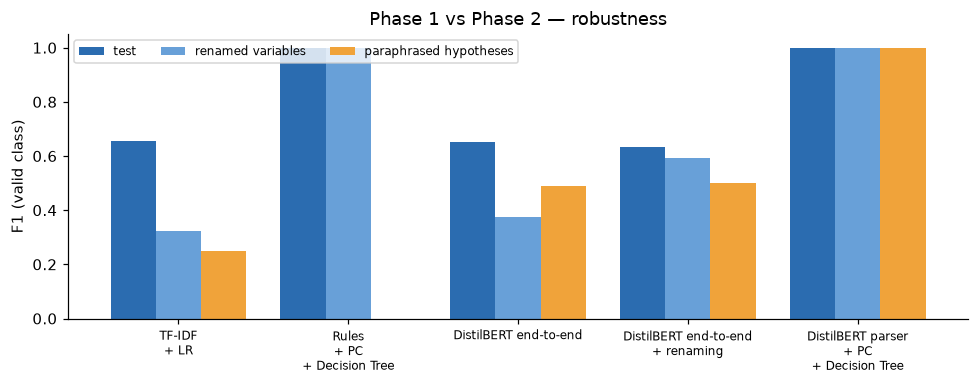

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.6))
plot = final.set_index("model")[[f"{s}_f1" for s in ["test", "refactorization", "paraphrase"]]]
plot.columns = ["test", "renamed variables", "paraphrased hypotheses"]
plot.plot.bar(ax=ax, width=0.8, color=["#2b6cb0", "#68a0d8", "#f0a33a"])
ax.set_ylabel("F1 (valid class)"); ax.set_ylim(0, 1.05); ax.set_xlabel("")
ax.set_xticklabels([m.replace(" + ", "\n+ ") for m in plot.index], rotation=0, fontsize=8)
ax.legend(loc="upper left", fontsize=8, ncol=3); ax.set_title("Phase 1 vs Phase 2 — robustness")
plt.tight_layout(); plt.savefig(RESULTS / "phase2_comparison.png", dpi=150); plt.savefig(FIGURES / "fig2_robustness.pdf"); plt.show()

## 8. Take-aways for the viva
1. **DistilBERT end-to-end (2A) ties TF-IDF in-distribution** (test F1 0.65 vs 0.66) and stays far below the
   rule-based reasoner (0.997). It has to *learn* causal discovery from 12 k examples and does not get there. It is
   more robust to wording than TF-IDF, though: paraphrase F1 0.49 vs 0.25.
2. **Renaming augmentation fixes a shortcut.** Without it the model leans on letter order: refactorization
   (renamed variables) F1 is 0.38. With it, 0.59 — for a 0.02 drop on the normal test set.
3. **The hybrid DL system (2B) gets the best of both.** DistilBERT handles the *language* (the parser reads
   100 % of paraphrased and unseen-verb hypotheses, the Phase 1 regex 0 %), the PC rules + tree handle the *reasoning*.
   Paraphrase F1 goes from **0.00 (Phase 1) to 0.997**, graphs from 0/73 to 73/73 correct edges.
4. **Structure is a product, not just a score.** Only the hybrid systems output triples, so only they build
   DAGs, Bayesian networks and answer do-queries — and 2B can do so from paraphrased text (query accuracy 0.63 → 0.975).
5. **Honest limits.** The paraphrase test has only 4 wordings; our parser was checked on extra unseen verbs and demo
   sentences, but free text would need a richer grammar or real annotated data. The parser expects exactly two
   variables, so a sentence naming a third is rejected. The training grammar was written knowing the test vocabulary
   existed, so we banned those words instead of imitating them. 2A was trained small (laptop).